# WP12 — Yeniden ölçüm ve AppContainer erişim teşhisi
Bu notebook yalnız gerçek QA kayıtlarını okur. Smoke test, inference veya yeni model indirme içermez. Bütün önceki sonuçlar ve19 senaryo korunur.

,Zaman,Boş RAM GiB,Boş VRAM MiB,Bellek kapısı
0,2026-11-08T03:36:11.462507+03:00,0.534618,3935,False


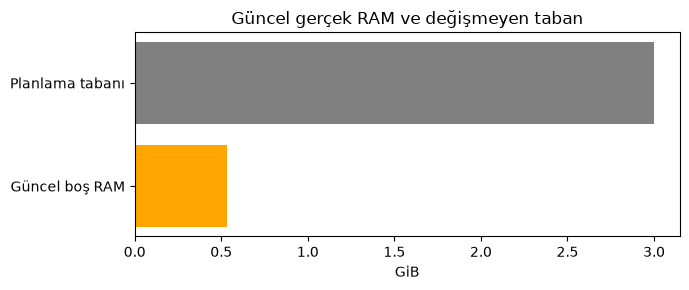

In [1]:
from pathlib import Path
import json,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd();Q=ROOT/'reports/qa/WP12/local_llm_recheck_v1'
r=json.loads((Q/'recheck.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'Zaman':r['captured_at'],'Boş RAM GiB':r['RAM']['available']/2**30,'Boş VRAM MiB':r['GPU']['free_MiB'],'Bellek kapısı':r['memory_gate_passed']}]))
fig,ax=plt.subplots(figsize=(7,3));ax.barh(['Güncel boş RAM','Planlama tabanı'],[r['RAM']['available']/2**30,3],color=['orange','grey']);ax.set_xlabel('GiB');ax.set_title('Güncel gerçek RAM ve değişmeyen taban')
F=ROOT/'reports/figures/WP12/local_llm_recheck_v1';F.mkdir(parents=True,exist_ok=True);fig.tight_layout();fig.savefig(F/'RAM_recheck.png',dpi=150);plt.show()

**Yorum:** RAM kapısı sağlanmıyor; VRAM boşluğu host RAM koşulunun yerine geçmez. Çizim LLM tepe bellek ölçümü değildir; LLM yüklenmedi.

In [2]:
for key in ['process_token','TCP_probe','API_version','listener_visibility','loopback_exemption_read_query']:
 print(key);display(pd.DataFrame([r[key]]) if isinstance(r[key],dict) else r[key])
display(pd.DataFrame([json.loads((Q/'diagnostic_interpretation.json').read_text(encoding='utf-8'))]).T)

process_token
TCP_probe
API_version
listener_visibility
loopback_exemption_read_query


,query_ok,is_appcontainer,last_error,method
0,True,True,None,GetTokenInformation(TokenIsAppContainer=29); T...


,status,errno,winerror,error
0,FAILED,13,10013,[WinError 10013] An attempt was made to access...


,error_type,error
0,URLError,<urlopen error [WinError 10013] An attempt was...


'UNVERIFIED_QUERY_FAILED'

,command,exit_code,stdout,stderr,configuration_modified
0,CheckNetIsolation.exe LoopbackExempt -s,5,"Error: Access Denied, run the command as an ad...",,False


,0
confirmed,"[Calling process token is AppContainer, TCP lo..."
inference,Sandbox/AppContainer network isolation is a li...
unverified,"[exact denying filter/firewall rule, loopback ..."
not_evidence_for,"[model corruption, port conflict, Ollama defin..."
diagnostic_note,First ad-hoc ctypes token query had handle sig...
sources,[https://learn.microsoft.com/en-us/windows/win...


**Yorum:** AppContainer=true ve TCP/HTTP erişim reddi gerçek bulgulardır. Belirli WFP kuralı veya firewall yapılandırması doğrulanmadı. Dinleyici görünürlüğünün kapalı olması, Ollama servisinin yokluğunu kanıtlamaz. Güvenlik ayarı değiştirilmedi.

In [3]:
display(pd.DataFrame([json.loads((Q/'decision.json').read_text(encoding='utf-8'))]).T)
display(pd.DataFrame([json.loads((Q/'frozen_inputs_check.json').read_text(encoding='utf-8'))]).T)
for name in ['test_wp12_llm_contract.py.log','test_wp12_llm_preflight.py.log']:
 print(name);print((Q/name).read_text(encoding='utf-8'))

test_wp12_llm_contract.py.log
test_01_all44_exact_spans (test_wp12_llm_contract.ContractTests.test_01_all44_exact_spans) ... ok
test_02_pending_not_semantic_pass (test_wp12_llm_contract.ContractTests.test_02_pending_not_semantic_pass) ... ok
test_03_missing_evidence (test_wp12_llm_contract.ContractTests.test_03_missing_evidence) ... ok
test_04_unknown_evidence (test_wp12_llm_contract.ContractTests.test_04_unknown_evidence) ... ok
test_05_unselected_real_evidence (test_wp12_llm_contract.ContractTests.test_05_unselected_real_evidence) ... ok
test_06_no_model_branch (test_wp12_llm_contract.ContractTests.test_06_no_model_branch) ... ok
test_07_no_model_or_label_fields (test_wp12_llm_contract.ContractTests.test_07_no_model_or_label_fields) ... ok
test_08_class_scope_not_direct (test_wp12_llm_contract.ContractTests.test_08_class_scope_not_direct) ... ok
test_09_class_context_required (test_wp12_llm_contract.ContractTests.test_09_class_context_required) ... ok
test_10_renal_exception_required

,0
status,STOPPED_RAM_OR_LOCAL_API_GATE
memory_gate_passed,False
API_access_verified,False
planning_thresholds,"{'host_available_GiB_at_least': 3.0, 'GPU_free..."
smoke_test,NOT_RUN_PRECONDITIONS_FAILED
real_scenarios,NOT_RUN_SMOKE_NOT_PASSED
model_loads,0
inference_calls,0
processes_terminated,0
security_changes,0


,0
scenarios,19
planned_repeats,3
source_file,reports/qa/WP12/llm_design_v1/frozen_scenarios...
sha256,6b17f8c306c5c39c70e5a160ab001bdb2ceff2b5b5fbba...
matches_previous_approved_candidate_record,True
contract_sha256,ddd7d292576f6c984a3530bf11463f32010b1287aa781f...
contract_unchanged,True


**Yorum:**24+6 test yalnız offline kontrollerdir.19×3 çalışma ve smoke test için gerçek çıktı yoktur; NA/NOT_RUN başarı sıfırı değildir. Kaynak, semantik inceleme ve otomatik yayın kapıları değişmedi. WP13 başlamadan burada durulur.